# 03 — Predictive Modeling

The predictive objective is to estimate whether a customer will visit using pretreatment attributes. Treatment assignment, visit, conversion, and spend are excluded from the feature set to prevent leakage.

The notebook reuses saved model bundles and saved held-out metrics rather than retraining unnecessarily.

In [1]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
import pandas as pd
from IPython.display import display, Image
metrics = pd.read_csv(ROOT / "reports/model_comparison.csv")
features = ["recency", "history", "history_segment", "mens", "womens", "zip_code", "newbie", "channel"]
print("Pretreatment features:", features)
display(metrics[["model", "roc_auc", "precision", "recall", "f1", "log_loss", "brier_score"]])

Pretreatment features: ['recency', 'history', 'history_segment', 'mens', 'womens', 'zip_code', 'newbie', 'channel']


,model,roc_auc,precision,recall,f1,log_loss,brier_score
0,logistic_regression,0.626738,0.0,0.0,0.0,0.404858,0.122336
1,decision_tree,0.606216,0.0,0.0,0.0,0.407868,0.124972


## Preprocessing and models

I use a scikit-learn `ColumnTransformer` and `Pipeline`. Numeric fields are scaled for logistic regression. Categorical fields are one-hot encoded with unknown categories ignored. Logistic regression provides an interpretable linear probability ranking; decision tree captures nonlinear interactions but can overfit. I use the validation split to select hyperparameters and evaluate the held-out test split once.

In [2]:
from marketing_ab.machine_learning import MODEL_FEATURES
print("Module feature list:", MODEL_FEATURES)
print("Post-treatment fields are excluded: visit, conversion, spend")

Module feature list: ('recency', 'history', 'mens', 'womens', 'newbie', 'history_segment', 'zip_code', 'channel')
Post-treatment fields are excluded: visit, conversion, spend


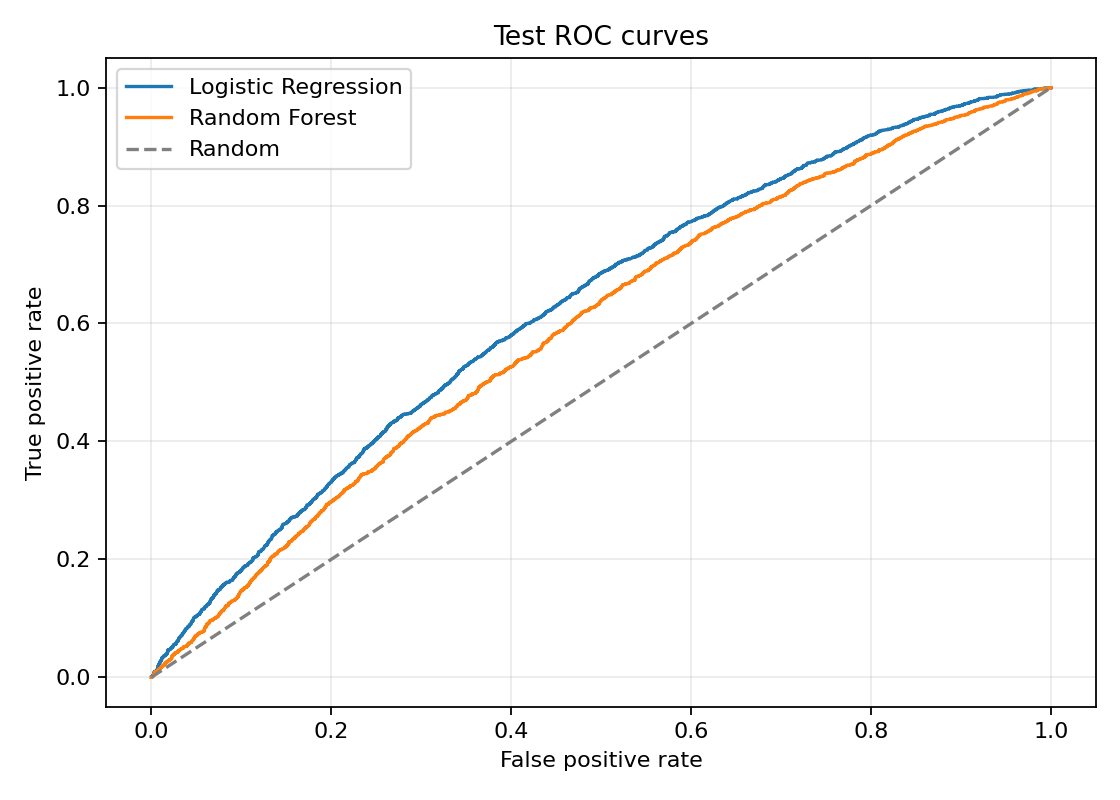

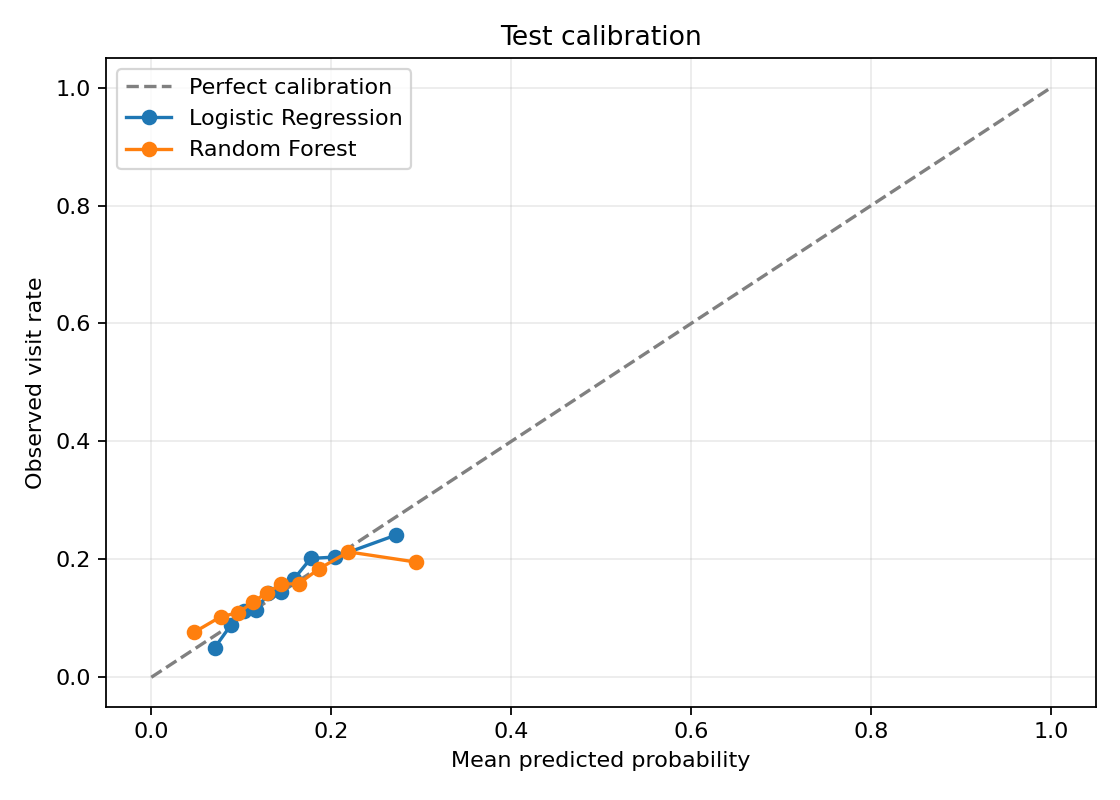

In [3]:
display(Image(filename=str(ROOT / "reports/figures/model_roc_curves.png")))
display(Image(filename=str(ROOT / "reports/figures/model_calibration.png")))

## Interpreting performance

Logistic regression has held-out ROC-AUC 0.627 versus 0.593 for decision tree. Both models have zero recall at the default 0.50 threshold because visits are relatively uncommon and the predicted probabilities remain below that cutoff. Ranking and probability quality therefore matter more than an unadjusted yes/no threshold.

## Key Findings

- Logistic regression is the stronger baseline on the saved held-out metrics.
- Predictive performance is modest, not a guarantee of individual behavior.
- Calibration, log loss, and Brier score complement ROC-AUC.
- Predictive modeling estimates likely visitors; it does not estimate incremental treatment effects.